<a href="https://colab.research.google.com/github/nourhnnan/sentiment-analysis-project/blob/main/sentimentProject_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q kagglehub

import os, re, glob, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, classification_report, confusion_matrix)

In [2]:
path = kagglehub.dataset_download("yacharki/amazon-reviews-for-sa-binary-negative-positive-csv")
train_path = glob.glob(path + "/**/train.csv", recursive=True)[0]
print(train_path)
print(pd.read_csv(train_path, header=None, nrows=3))

100%|██████████| 667M/667M [00:08<00:00, 82.4MB/s]

Extracting files...


/root/.cache/kagglehub/datasets/yacharki/amazon-reviews-for-sa-binary-negative-positive-csv/versions/5/amazon_review_sa_binary_csv/train.csv
             0                                      1  \
0  class_index                           review_title   
1            2         Stuning even for the non-gamer   
2            2  The best soundtrack ever to anything.   

                                                   2  
0                                        review_text  
1  This sound track was beautiful! It paints the ...  
2  I'm reading a lot of reviews saying that this ...  


In [3]:
parts = []
for chunk in pd.read_csv(train_path, chunksize=200_000):
    parts.append(chunk.sample(frac=0.03, random_state=42))

sample = pd.concat(parts, ignore_index=True)
sample["label"] = sample["class_index"].map({1: 0, 2: 1})

print(sample.shape)
print(sample["label"].value_counts(normalize=True))
sample.head()

(108000, 4)
label
1    0.501176
0    0.498824
Name: proportion, dtype: float64


,class_index,review_title,review_text,label
0,2,The Sweet Smell of Christmas,My gradchildren love this book and have scratc...,1
1,2,given the terrible circumstances...,The Beatles were on their last legs during the...,1
2,2,Your Eyes'll Be Glued To This Book!!,"""SHILOH"" is a great book for all ages! Well, n...",1
3,2,Quite good -- if only there were more examples...,"First, I unequivocally recommend this book to ...",1
4,1,Disappointed,I bought 2 of these discs. Both seem like bad ...,0


In [4]:
print(sample.isnull().sum())
print(sample.duplicated(subset=["review_title", "review_text"]).sum())

class_index     0
review_title    8
review_text     0
label           0
dtype: int64
0


In [5]:
sample["review_title"] = sample["review_title"].fillna("")
sample["review"] = sample["review_title"] + " " + sample["review_text"]

def clean_text(text):
    text = text.lower()
    text = re.sub(r"<.*?>", " ", text)
    text = re.sub(r"http\S+", " ", text)
    text = re.sub(r"[^a-z\s']", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

sample["clean_review"] = sample["review"].apply(clean_text)

print(sample[["review", "clean_review"]].head())
print((sample["clean_review"].str.len() == 0).sum())

                                              review  \
0  The Sweet Smell of Christmas My gradchildren l...   
1  given the terrible circumstances... The Beatle...   
2  Your Eyes'll Be Glued To This Book!! "SHILOH" ...   
3  Quite good -- if only there were more examples...   
4  Disappointed I bought 2 of these discs. Both s...   

                                        clean_review  
0  the sweet smell of christmas my gradchildren l...  
1  given the terrible circumstances the beatles w...  
2  your eyes'll be glued to this book shiloh is a...  
3  quite good if only there were more examples fi...  
4  disappointed i bought of these discs both seem...  
0


In [6]:
X = sample["clean_review"]
y = sample["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

(86400,) (21600,)
label
1    0.501181
0    0.498819
Name: proportion, dtype: float64
label
1    0.501157
0    0.498843
Name: proportion, dtype: float64


In [7]:
k1, b = 1.5, 0.75

def fit_bm25(texts):
    vec = CountVectorizer(max_features=50000)
    counts = vec.fit_transform(texts)
    N = counts.shape[0]
    df = np.bincount(counts.indices, minlength=counts.shape[1])
    idf = np.log((N - df + 0.5) / (df + 0.5) + 1)
    avgdl = counts.sum(axis=1).mean()
    return vec, counts, idf, avgdl

def bm25_apply(counts, idf, avgdl):
    X = counts.tocsr().astype(float)
    dl = np.asarray(X.sum(axis=1)).ravel()
    row_ids = np.repeat(np.arange(X.shape[0]), np.diff(X.indptr))
    tf = X.data
    X.data = idf[X.indices] * tf * (k1 + 1) / (tf + k1 * (1 - b + b * dl[row_ids] / avgdl))
    return X

count_vec, train_counts, idf, avgdl = fit_bm25(X_train)
X_train_vec = bm25_apply(train_counts, idf, avgdl)
X_test_vec = bm25_apply(count_vec.transform(X_test), idf, avgdl)

print(X_train_vec.shape)
print(X_test_vec.shape)

(86400, 50000)
(21600, 50000)


In [8]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Naive Bayes": MultinomialNB(),
    "Linear SVM": LinearSVC(),
}

rows, trained, preds = [], {}, {}
for name, m in models.items():
    t = time.time()
    m.fit(X_train_vec, y_train)
    train_time = time.time() - t
    p = m.predict(X_test_vec)
    trained[name], preds[name] = m, p
    rows.append({
        "Model": name,
        "Train accuracy": accuracy_score(y_train, m.predict(X_train_vec)),
        "Test accuracy": accuracy_score(y_test, p),
        "Precision": precision_score(y_test, p),
        "Recall": recall_score(y_test, p),
        "F1": f1_score(y_test, p),
        "Macro-F1": f1_score(y_test, p, average="macro"),
        "Balanced accuracy": balanced_accuracy_score(y_test, p),
        "Recall (negative)": recall_score(y_test, p, pos_label=0),
        "Train time (s)": round(train_time, 1),
    })

results = pd.DataFrame(rows).set_index("Model").round(4)
results

/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


,Train accuracy,Test accuracy,Precision,Recall,F1,Macro-F1,Balanced accuracy,Recall (negative),Train time (s)
Model,,,,,,,,,
Logistic Regression,0.9984,0.8544,0.8550,0.8543,0.8546,0.8544,0.8544,0.8544,9.6
Naive Bayes,0.8962,0.8162,0.8323,0.7929,0.8121,0.8161,0.8162,0.8395,0.1
Linear SVM,1.0000,0.8254,0.8255,0.8263,0.8259,0.8254,0.8254,0.8245,168.8


In [9]:
for name in models:
    print("=" * 50)
    print(name)
    print(classification_report(y_test, preds[name]))
    print(confusion_matrix(y_test, preds[name]))

best_name = results["Test accuracy"].idxmax()
print("\nBest model:", best_name)

Logistic Regression
              precision    recall  f1-score   support

           0       0.85      0.85      0.85     10775
           1       0.85      0.85      0.85     10825

    accuracy                           0.85     21600
   macro avg       0.85      0.85      0.85     21600
weighted avg       0.85      0.85      0.85     21600

[[9206 1569]
 [1577 9248]]
Naive Bayes
              precision    recall  f1-score   support

           0       0.80      0.84      0.82     10775
           1       0.83      0.79      0.81     10825

    accuracy                           0.82     21600
   macro avg       0.82      0.82      0.82     21600
weighted avg       0.82      0.82      0.82     21600

[[9046 1729]
 [2242 8583]]
Linear SVM
              precision    recall  f1-score   support

           0       0.83      0.82      0.82     10775
           1       0.83      0.83      0.83     10825

    accuracy                           0.83     21600
   macro avg       0.83      0.

In [10]:
reviews = [
    "This product is amazing, I love it",
    "Terrible quality, it broke after one day",
    "NOT BAD AT ALL",
]
cleaned = [clean_text(r) for r in reviews]
vec = bm25_apply(count_vec.transform(cleaned), idf, avgdl)

for name, m in trained.items():
    print(name, m.predict(vec))

Logistic Regression [1 0 0]
Naive Bayes [1 0 0]
Linear SVM [1 0 0]


In [11]:
X_sub, X_val, y_sub, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42, stratify=y_train
)

sub_vec, sub_counts, idf_sub, avgdl_sub = fit_bm25(X_sub)
X_sub_vec = bm25_apply(sub_counts, idf_sub, avgdl_sub)
X_val_vec = bm25_apply(sub_vec.transform(X_val), idf_sub, avgdl_sub)

print(X_sub_vec.shape, X_val_vec.shape)
print(y_sub.value_counts(normalize=True))
print(y_val.value_counts(normalize=True))

(69120, 50000) (17280, 50000)
label
1    0.501186
0    0.498814
Name: proportion, dtype: float64
label
1    0.501157
0    0.498843
Name: proportion, dtype: float64


In [12]:
def sweep(make_model, values):
    tr, va = [], []
    for v in values:
        m = make_model(v)
        m.fit(X_sub_vec, y_sub)
        tr.append(accuracy_score(y_sub, m.predict(X_sub_vec)))
        va.append(accuracy_score(y_val, m.predict(X_val_vec)))
    out = pd.DataFrame({"value": values, "Train": tr, "Validation": va}).round(4)
    out["Gap"] = (out["Train"] - out["Validation"]).round(4)
    return out

def plot_sweep(table, title, xlabel):
    plt.figure(figsize=(7, 4))
    plt.plot(range(len(table)), table["Train"], marker="o", label="Train")
    plt.plot(range(len(table)), table["Validation"], marker="o", label="Validation")
    plt.xticks(range(len(table)), table["value"], rotation=45)
    plt.xlabel(xlabel)
    plt.ylabel("Accuracy")
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.show()

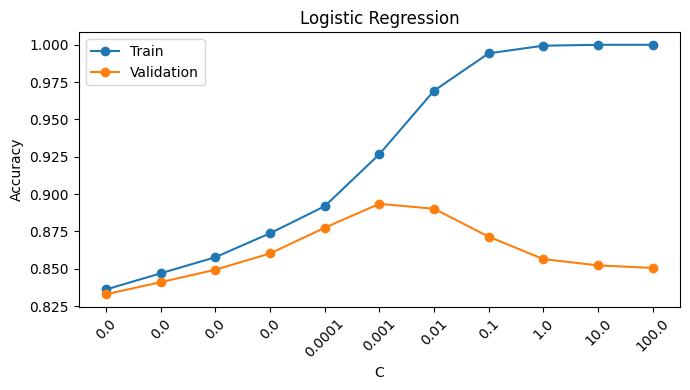

,value,Train,Validation,Gap
0,0.0000,0.8362,0.8330,0.0032
1,0.0000,0.8470,0.8411,0.0059
2,0.0000,0.8578,0.8494,0.0084
3,0.0000,0.8738,0.8603,0.0135
4,0.0001,0.8919,0.8775,0.0144
5,0.0010,0.9267,0.8935,0.0332
6,0.0100,0.9692,0.8902,0.0790
7,0.1000,0.9942,0.8715,0.1227
8,1.0000,0.9993,0.8565,0.1428
9,10.0000,0.9999,0.8523,0.1476


In [13]:
C_lr = [0.000001, 0.000003, 0.00001, 0.00003, 0.0001, 0.001, 0.01, 0.1, 1, 10, 100]
lr_sweep = sweep(lambda v: LogisticRegression(C=v, max_iter=1000), C_lr)
plot_sweep(lr_sweep, "Logistic Regression", "C")
lr_sweep

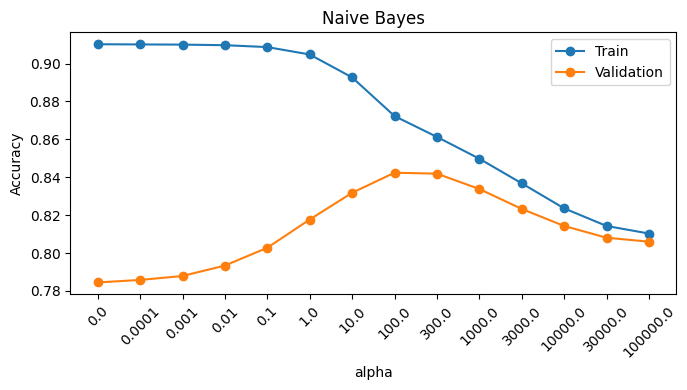

,value,Train,Validation,Gap
0,0.0000,0.9102,0.7845,0.1257
1,0.0001,0.9101,0.7858,0.1243
2,0.0010,0.9100,0.7879,0.1221
3,0.0100,0.9097,0.7934,0.1163
4,0.1000,0.9087,0.8028,0.1059
5,1.0000,0.9048,0.8177,0.0871
6,10.0000,0.8927,0.8318,0.0609
7,100.0000,0.8723,0.8424,0.0299
8,300.0000,0.8613,0.8419,0.0194
9,1000.0000,0.8498,0.8338,0.0160


In [14]:
alpha_nb = [0.00001, 0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 300, 1000, 3000, 10000, 30000, 100000]
nb_sweep = sweep(lambda v: MultinomialNB(alpha=v), alpha_nb)
plot_sweep(nb_sweep, "Naive Bayes", "alpha")
nb_sweep

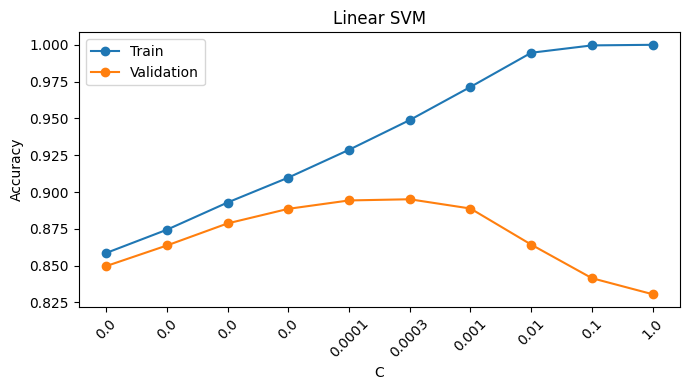

,value,Train,Validation,Gap
0,0.0000,0.8586,0.8497,0.0089
1,0.0000,0.8744,0.8637,0.0107
2,0.0000,0.8929,0.8787,0.0142
3,0.0000,0.9098,0.8886,0.0212
4,0.0001,0.9287,0.8943,0.0344
5,0.0003,0.9489,0.8951,0.0538
6,0.0010,0.9714,0.8888,0.0826
7,0.0100,0.9946,0.8643,0.1303
8,0.1000,0.9996,0.8415,0.1581
9,1.0000,1.0000,0.8306,0.1694


In [15]:
C_svm = [0.000001, 0.000003, 0.00001, 0.00003, 0.0001, 0.0003, 0.001, 0.01, 0.1, 1]
svm_sweep = sweep(lambda v: LinearSVC(C=v, max_iter=2000), C_svm)
plot_sweep(svm_sweep, "Linear SVM", "C")
svm_sweep

In [16]:
configs = [
    ("Logistic Regression", "Underfit", LogisticRegression(C=0.000001, max_iter=1000)),
    ("Logistic Regression", "Good fit", LogisticRegression(C=0.001, max_iter=1000)),
    ("Logistic Regression", "Overfit", LogisticRegression(C=100, max_iter=1000)),
    ("Naive Bayes", "Underfit", MultinomialNB(alpha=100000)),
    ("Naive Bayes", "Good fit", MultinomialNB(alpha=100)),
    ("Naive Bayes", "Overfit", MultinomialNB(alpha=0.00001)),
    ("Linear SVM", "Underfit", LinearSVC(C=0.000001, max_iter=2000)),
    ("Linear SVM", "Good fit", LinearSVC(C=0.0003, max_iter=2000)),
    ("Linear SVM", "Overfit", LinearSVC(C=1, max_iter=2000)),
]

final_rows = []
for algo, state, m in configs:
    t = time.time()
    m.fit(X_train_vec, y_train)
    tr = accuracy_score(y_train, m.predict(X_train_vec))
    te = accuracy_score(y_test, m.predict(X_test_vec))
    final_rows.append({
        "Algorithm": algo,
        "State": state,
        "Train": round(tr, 4),
        "Test": round(te, 4),
        "Gap": round(tr - te, 4),
        "Time (s)": round(time.time() - t, 1),
    })

final_table = pd.DataFrame(final_rows)
final_table

,Algorithm,State,Train,Test,Gap,Time (s)
0,Logistic Regression,Underfit,0.8386,0.8355,0.0031,0.8
1,Logistic Regression,Good fit,0.9255,0.8977,0.0278,1.6
2,Logistic Regression,Overfit,0.9997,0.8462,0.1534,6.0
3,Naive Bayes,Underfit,0.8083,0.8028,0.0055,0.2
4,Naive Bayes,Good fit,0.8700,0.8417,0.0283,0.1
5,Naive Bayes,Overfit,0.9003,0.7937,0.1065,0.1
6,Linear SVM,Underfit,0.8600,0.8568,0.0032,0.8
7,Linear SVM,Good fit,0.9462,0.8975,0.0487,3.1
8,Linear SVM,Overfit,1.0000,0.8249,0.1751,226.6


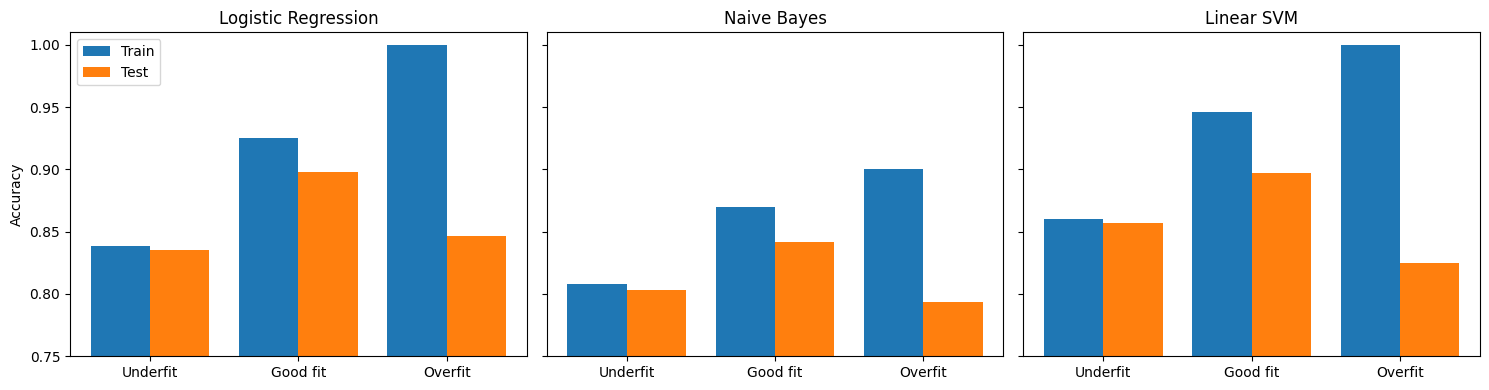

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
order = ["Underfit", "Good fit", "Overfit"]

for ax, algo in zip(axes, ["Logistic Regression", "Naive Bayes", "Linear SVM"]):
    d = final_table[final_table["Algorithm"] == algo].set_index("State").loc[order]
    x = range(3)
    ax.bar([i - 0.2 for i in x], d["Train"], width=0.4, label="Train")
    ax.bar([i + 0.2 for i in x], d["Test"], width=0.4, label="Test")
    ax.set_xticks(list(x))
    ax.set_xticklabels(order)
    ax.set_title(algo)
    ax.set_ylim(0.75, 1.01)

axes[0].set_ylabel("Accuracy")
axes[0].legend()
plt.tight_layout()
plt.show()